<a href="https://colab.research.google.com/github/OliCamarera/ti2006b_2.6_A00843123/blob/main/03_colab_bridge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Activity 3 — Colab–VS Code Bridge

**Course:** TI2006B — Beginner Data-Science DevOps Workshop
**Notebook:** `notebooks/03_colab_bridge.ipynb`
**Author:** A00843123 · **Repository:** https://github.com/OliCamarera/ti2006b_2.6_A00843123

## Question
In a simulated group of students, **is there a positive relationship between weekly study hours and quiz score?**

## Data provenance
- The data are **100% synthetic**, generated inside this notebook with NumPy using a fixed random seed (`SEED = 2006`).
- No files are read, no Google Drive is mounted, and no personal, confidential, or real student data is used.
- Anyone who runs this notebook from a clean runtime will obtain exactly the same data.

## Expected output
1. A printout of the Python and package versions used.
2. A table of 60 synthetic records and their descriptive statistics.
3. The Pearson correlation and a simple linear-regression slope between study hours and quiz score.
4. A scatter plot with the fitted line.
5. A short written conclusion.

## How to run
Open from GitHub in Colab (or in VS Code), then **Runtime → Restart and run all**. All cells must run top-to-bottom from a fresh session; nothing depends on a previous session.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OliCamarera/ti2006b_2.6_A00843123/blob/main/notebooks/03_colab_bridge.ipynb)


## 1. Setup — environment and dependencies

In [ ]:
# Setup: record the environment so another person can reproduce the run.
# Required packages: numpy, pandas, matplotlib (all preinstalled in Google Colab).
# If running locally and any are missing, uncomment the next line:
# %pip install numpy pandas matplotlib

import sys
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# Detect which runtime is executing this notebook
try:
    import google.colab  # noqa: F401
    RUNTIME = "Google Colab (hosted runtime)"
except ImportError:
    RUNTIME = "Local / non-Colab runtime"

print("Runtime     :", RUNTIME)
print("Python      :", sys.version.split()[0])
print("Platform    :", platform.platform())
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("matplotlib  :", matplotlib.__version__)

Runtime     : Google Colab (hosted runtime)
Python      : 3.13.18
Platform    : Linux-6.6.159+-x86_64-with-glibc2.39
numpy       : 2.4.6
pandas      : 2.2.3
matplotlib  : 3.10.0


## 2. Synthetic data
Each row is a fictitious student. Score is generated as `50 + 3.5 × hours + noise`, clipped to 0–100.

In [ ]:
SEED = 2006          # fixed seed -> identical data on every run
N_STUDENTS = 60

rng = np.random.default_rng(SEED)
study_hours = rng.uniform(0, 12, N_STUDENTS).round(1)
noise = rng.normal(0, 8, N_STUDENTS)
quiz_score = np.clip(50 + 3.5 * study_hours + noise, 0, 100).round(1)

df = pd.DataFrame({
    "student_id": [f"S{i:03d}" for i in range(1, N_STUDENTS + 1)],
    "study_hours": study_hours,
    "quiz_score": quiz_score,
})

print("Shape:", df.shape)
df.head(10)

Shape: (60, 3)


,student_id,study_hours,quiz_score
0,S001,10.5,88.9
1,S002,6.7,70.9
2,S003,3.6,62.5
3,S004,4.3,61.9
4,S005,3.5,63.3
5,S006,11.5,92.7
6,S007,0.9,57.0
7,S008,4.9,70.7
8,S009,11.4,83.3
9,S010,10.4,100.0


In [ ]:
df[["study_hours", "quiz_score"]].describe().round(2)

,study_hours,quiz_score
count,60.00,60.00
mean,6.50,74.27
std,3.23,14.17
min,0.20,46.80
25%,3.58,62.75
50%,6.75,74.05
75%,9.12,83.68
max,11.50,100.00


## 3. Analysis

Pearson r          : 0.842
Regression line    : score = 50.31 + 3.69 * hours
Predicted @ 0 h    : 50.3
Predicted @ 10 h   : 87.2


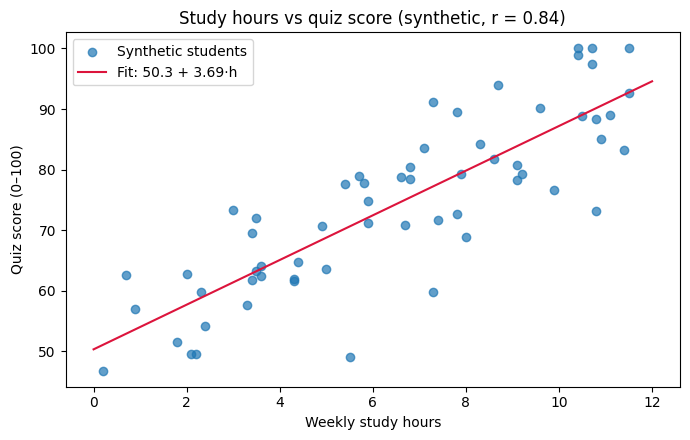

In [ ]:
r = df["study_hours"].corr(df["quiz_score"])           # Pearson correlation
slope, intercept = np.polyfit(df["study_hours"], df["quiz_score"], 1)

print(f"Pearson r          : {r:.3f}")
print(f"Regression line    : score = {intercept:.2f} + {slope:.2f} * hours")
print(f"Predicted @ 0 h    : {intercept:.1f}")
print(f"Predicted @ 10 h   : {intercept + slope * 10:.1f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(df["study_hours"], df["quiz_score"], alpha=0.7, label="Synthetic students")
xs = np.linspace(0, 12, 100)
ax.plot(xs, intercept + slope * xs, color="crimson", label=f"Fit: {intercept:.1f} + {slope:.2f}·h")
ax.set_xlabel("Weekly study hours")
ax.set_ylabel("Quiz score (0–100)")
ax.set_title(f"Study hours vs quiz score (synthetic, r = {r:.2f})")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Conclusion

In [ ]:
strength = "strong" if abs(r) >= 0.7 else "moderate" if abs(r) >= 0.4 else "weak"
print(f"In this synthetic sample there is a {strength} positive relationship (r = {r:.2f}).")
print(f"Each additional weekly study hour is associated with about {slope:.1f} more quiz points.")

In this synthetic sample there is a strong positive relationship (r = 0.84).
Each additional weekly study hour is associated with about 3.7 more quiz points.


**Conclusion.** In this synthetic data set, study hours and quiz score show a clear positive relationship, which is expected because the data were generated with a positive slope (3.5 points per hour) plus random noise. The estimated slope is close to that value, which confirms the analysis recovers the known pattern. Because the data are simulated, **this result says nothing about real students**; the goal of the notebook is to demonstrate a reproducible GitHub → Colab → GitHub workflow, not to make an empirical claim.

## 5. Saved content vs. runtime state
- **Saved in this `.ipynb` (shared via GitHub):** the code, these Markdown explanations, and the outputs from the last run (tables, printed values, the plot).
- **Not saved / not shared:** the live runtime — variables in memory, installed packages, the Python process, and any files on the Colab VM or my computer. Another person who opens this notebook sees my outputs but must **re-run all cells** to recreate the state. That is why the setup cell records versions and the data are generated with a fixed seed instead of being loaded from a local path.
